In [2]:
import json
import csv
import random
from pathlib import Path
from matplotlib.patches import Patch

import numpy as np
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch
from matplotlib.lines import Line2D

CURRENT_DIR = Path.cwd().resolve()
BASE_DIR_CANDIDATES = [
    CURRENT_DIR,
    CURRENT_DIR.parent,
    CURRENT_DIR / 'CostPlanner',
    CURRENT_DIR.parent / 'CostPlanner',
]
RESULTS_DIR = next(
    (base_dir / 'schedule_results' for base_dir in BASE_DIR_CANDIDATES
     if (base_dir / 'schedule_results').is_dir()),
    None,
)
if RESULTS_DIR is None:
    raise FileNotFoundError(f'Could not find schedule_results from {CURRENT_DIR}')
OUTPUT_DIR = RESULTS_DIR.parent / 'Exp_plot'

def load_hourly_results(algorithm):
    file_path = RESULTS_DIR / f'{algorithm}_results.csv'
    with file_path.open('r', encoding='utf-8-sig', newline='') as file:
        results = list(csv.DictReader(file))
    for item in results:
        item['Hour'] = int(item['Hour'])
        item['Comp_Task_NUM'] = int(item['Comp_Task_NUM'])
        item['ECost'] = float(item['ECost'])
    return sorted(results, key=lambda item: item['Hour'])

CostPlanner_MCMF_dict = load_hourly_results('CostPlannerFlow')
LowestCostFirst_dict = load_hourly_results('LowestCostFirst')
LowestEConFirst_dict = load_hourly_results('LowestEConFirst')
TanGo_dict = load_hourly_results('TanGo')
MAST_dict = load_hourly_results('MAST')


In [3]:
LowestCostFirst_list = []
LowestCostFirst_Cost_list = []
LowestEConFirst_list = []
LowestEConFirst_Cost_list = []
CostPlanner_MCMF_list = []
CostPlanner_MCMF_Cost_list = []
MAST_list = []
MAST_Cost_list = []
Hour_list = [hour for hour in range(0, 24)]
for item in LowestCostFirst_dict:
    LowestCostFirst_list.append(item)
    LowestCostFirst_Cost_list.append(item['ECost'])
for item in LowestEConFirst_dict:
    LowestEConFirst_list.append(item)
    LowestEConFirst_Cost_list.append(item['ECost'])
for item in CostPlanner_MCMF_dict:
    CostPlanner_MCMF_list.append(item)
    CostPlanner_MCMF_Cost_list.append(item['ECost'])
for item in MAST_dict:
    MAST_list.append(item)
    MAST_Cost_list.append(item['ECost'])


In [4]:
Tango_list = TanGo_dict
Tango_Cost_list = [item['ECost'] for item in Tango_list]


In [5]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
rcParams['font.family'] = 'Times New Roman'
rcParams['font.size'] = 18

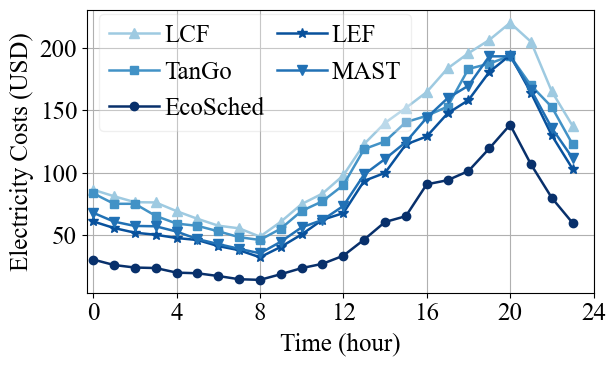

220.03660285273563

In [6]:
plt.figure(figsize=(6.5, 4))

plt.plot(Hour_list, LowestCostFirst_Cost_list, marker='^', linewidth=1.8, markersize=7, label='LCF', color='#9ECAE1')
plt.plot(Hour_list, Tango_Cost_list, marker='s', linewidth=1.8, markersize=6, label='TanGo', color='#4292C6')
plt.plot(Hour_list, CostPlanner_MCMF_Cost_list, marker='o', linewidth=1.8, markersize=6, label='EcoSched', color='#08306B')
plt.plot(Hour_list, LowestEConFirst_Cost_list, marker='*', linewidth=1.8, markersize=7, label='LEF', color='#08519C')
plt.plot(Hour_list, MAST_Cost_list, marker='v', linewidth=1.8, markersize=7, label='MAST', color='#2171B5')

color_MCMF_list = ['#9ECAE1', '#4292C6', '#2171B5', '#08519C', '#08306B']

plt.xlabel('Time (hour)')
plt.ylabel('Electricity Costs (USD)')
plt.xticks([0, 4, 8, 12, 16, 20, 24])
plt.xlim(-0.3, 24)
plt.legend(ncol=2, loc='upper left', framealpha=0.3,  bbox_to_anchor=(0, 1.03), columnspacing=0.5, handletextpad=0.2)
plt.grid(True)
plt.tight_layout()

plt.savefig(OUTPUT_DIR / 'Electrity_Hour_Costs.pdf', format='pdf', bbox_inches='tight')
plt.show()
LowestCostFirst_Cost_list[-4]

In [7]:
LowestCostFirst_Cost_sum = sum(LowestCostFirst_Cost_list) / 24
LowestEConFirst_Cost_sum = sum(LowestEConFirst_Cost_list) / 24
CostPlanner_MCMF_Cost_sum = sum(CostPlanner_MCMF_Cost_list) / 24
LowestCostFirst_Cost_sum, LowestEConFirst_Cost_sum, CostPlanner_MCMF_Cost_sum

(117.68303890940369, 90.36353279088547, 52.34839215617237)

In [8]:
number_bar = [LowestCostFirst_list[5]['Comp_Task_NUM'], LowestCostFirst_list[14]['Comp_Task_NUM'], LowestCostFirst_list[20]['Comp_Task_NUM']]
number_bar = [int(round(item / 1000, 0)) * 1000 for item in number_bar]
LowestCostFirst_Cost_bar = [LowestCostFirst_Cost_list[5], LowestCostFirst_Cost_list[14], LowestCostFirst_Cost_list[20]]
LowestEConFirst_Cost_bar = [LowestEConFirst_list[5]['ECost'], LowestEConFirst_list[14]['ECost'], LowestEConFirst_list[20]['ECost']]
Tango_Cost_bar = [Tango_Cost_list[5], Tango_Cost_list[14], Tango_Cost_list[20]]
MAST_Cost_bar = [MAST_list[5]['ECost'], MAST_list[14]['ECost'], MAST_list[20]['ECost']]
CostPlanner_MCMF_Cost_bar = [CostPlanner_MCMF_list[5]['ECost'], CostPlanner_MCMF_list[14]['ECost'], CostPlanner_MCMF_list[20]['ECost']]

transfer_baseline_file = RESULTS_DIR / 'transfer_results' / 'transfer_summary.csv'
with transfer_baseline_file.open('r', encoding='utf-8-sig', newline='') as file:
    transfer_baseline_rows = list(csv.DictReader(file))

transfer_baseline_costs = {}
for item in transfer_baseline_rows:
    if (
        int(item['Workload_Hour']) == 14
        and int(item['Workload_Count']) == 6000
        and item['Experiment'] == 'data_volume_multiplier'
        and float(item['Data_Volume_Multiplier']) == 1.0
        and float(item['Bandwidth_Gbps']) == 50.0
    ):
        transfer_baseline_costs[item['Algorithm']] = float(item['ECost'])

expected_baseline_algorithms = {
    'LowestCostFirst', 'LowestEConFirst', 'TanGo', 'MAST', 'CostPlanner'
}
if set(transfer_baseline_costs) != expected_baseline_algorithms:
    raise ValueError('Expected one 6000-workload baseline for each algorithm at 1x and 50 Gbps')

if 6000 not in number_bar:
    raise ValueError('The workload-count chart must include 6000 workloads')
baseline_index = number_bar.index(6000)
for algorithm, cost_values in [
    ('LowestCostFirst', LowestCostFirst_Cost_bar),
    ('LowestEConFirst', LowestEConFirst_Cost_bar),
    ('TanGo', Tango_Cost_bar),
    ('MAST', MAST_Cost_bar),
    ('CostPlanner', CostPlanner_MCMF_Cost_bar),
]:
    cost_values[baseline_index] = transfer_baseline_costs[algorithm]


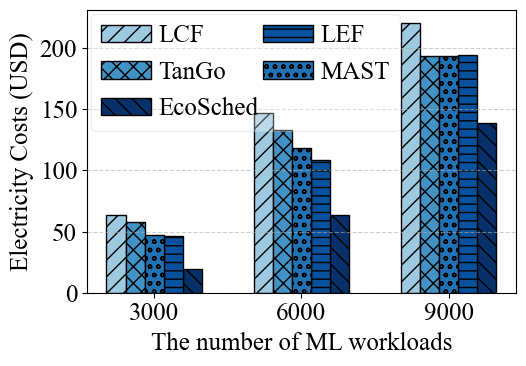

([3.2349939471756723, 2.3104645262709274, 1.5891928252403158],
 [2.9459775028786597, 2.089132687450594, 1.398605964171252],
 [2.3640616274638626, 1.7009873975583196, 1.4025686657675627],
 [2.4029676135237388, 1.8634500286749187, 1.3955974811782832])

In [9]:
import matplotlib.pyplot as plt
import numpy as np

task_nums = number_bar

LCF = LowestCostFirst_Cost_bar
LEF = LowestEConFirst_Cost_bar
TanGO = Tango_Cost_bar
MAST = MAST_Cost_bar
EcoSched = CostPlanner_MCMF_Cost_bar

# 设置柱宽和位置
bar_width = 0.13
x = np.arange(len(task_nums))  # [0, 1, 2]
# 绘图
plt.figure(figsize=(5.6, 4))
plt.bar(x - 2 * bar_width, LCF, width=bar_width, color='#9ECAE1', label='LCF', edgecolor='black', hatch='//')
plt.bar(x - bar_width, TanGO, width=bar_width, color='#4292C6', label='TanGo', edgecolor='black', hatch='xx')
plt.bar(x + 2 * bar_width, EcoSched, width=bar_width, color='#08306B', label='EcoSched', edgecolor='black', hatch='\\\\')
plt.bar(x + bar_width, LEF, width=bar_width, color='#08519C', label='LEF', edgecolor='black', hatch='--')
plt.bar(x, MAST, width=bar_width, color='#2171B5', label='MAST', edgecolor='black', hatch='oo')


color_MCMF_list = ['#9ECAE1', '#4292C6', '#2171B5', '#08519C', '#08306B']

# 添加x轴刻度和标签
plt.xticks(x, task_nums)
plt.xlabel('The number of ML workloads')
plt.ylabel('Electricity Costs (USD)')
plt.legend(ncol=2, loc='upper left', bbox_to_anchor=(-0.02, 1.03), framealpha=0.3, columnspacing=0.2, handletextpad=0.3)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()

plt.savefig(OUTPUT_DIR / 'Electrity_Costs.pdf', format='pdf', bbox_inches='tight')
plt.show()

x_LCF = [p / a for a, p in zip(EcoSched, LCF)]
x_TanGo = [p / a for a, p in zip(EcoSched, TanGO)]
x_LEF = [p / a for a, p in zip(EcoSched, LEF)]
x_MAST = [p / a for a, p in zip(EcoSched, MAST)]
x_LCF, x_TanGo, x_LEF, x_MAST

In [10]:
import csv
TRANSFER_RESULTS_DIR = RESULTS_DIR / 'transfer_results'
TRANSFER_SUMMARY_FILE = TRANSFER_RESULTS_DIR / 'transfer_summary.csv'
with TRANSFER_SUMMARY_FILE.open('r', encoding='utf-8-sig', newline='') as file:
    transfer_rows = list(csv.DictReader(file))

TRANSFER_ALGORITHMS = ['LowestCostFirst', 'TanGo', 'MAST', 'LowestEConFirst', 'CostPlanner']
TRANSFER_VOLUME_LEVELS = [1, 3, 5]
TRANSFER_BANDWIDTH_LEVELS = [10, 30, 50]
if len(transfer_rows) != 45:
    raise ValueError(f'Expected 45 transfer results, found {len(transfer_rows)}')
if any(int(row['Workload_Hour']) != 14 or int(row['Workload_Count']) != 6000
       for row in transfer_rows):
    raise ValueError('Transfer results must use hour 14 and exactly 6000 workloads')


def transfer_cost(experiment, scenario_value, bandwidth, algorithm):
    matches = [
        row for row in transfer_rows
        if row['Experiment'] == experiment
        and float(row['Scenario_Value']) == float(scenario_value)
        and float(row['Bandwidth_Gbps']) == float(bandwidth)
        and row['Algorithm'] == algorithm
    ]
    if len(matches) != 1:
        raise ValueError(
            f'Expected one result for {experiment}={scenario_value}, '
            f'{bandwidth} Gbps, {algorithm}; found {len(matches)}'
        )
    return float(matches[0]['ECost'])


volume_costs = {
    algorithm: [
        transfer_cost('data_volume_multiplier', multiplier, 50, algorithm)
        for multiplier in TRANSFER_VOLUME_LEVELS
    ]
    for algorithm in TRANSFER_ALGORITHMS
}
bandwidth_costs = {
    algorithm: [
        transfer_cost(
            'data_volume_multiplier' if bandwidth == 50 else 'inter_region_bandwidth',
            1 if bandwidth == 50 else bandwidth,
            bandwidth,
            algorithm,
        )
        for bandwidth in TRANSFER_BANDWIDTH_LEVELS
    ]
    for algorithm in TRANSFER_ALGORITHMS
}

rcParams['font.size'] = 20


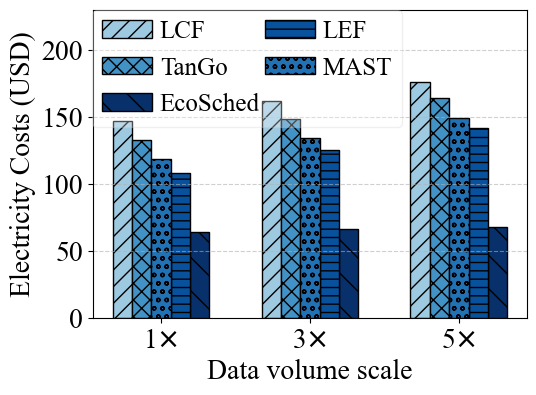

[63.65224469743709, 66.12245653340237, 67.42713061161248]

In [13]:
task_nums = [f'{multiplier}$\\times$' for multiplier in TRANSFER_VOLUME_LEVELS]
LCF = volume_costs['LowestCostFirst']
LEF = volume_costs['LowestEConFirst']
TanGO = volume_costs['TanGo']
MAST = volume_costs['MAST']
EcoSched = volume_costs['CostPlanner']

bar_width = 0.13
x = np.arange(len(task_nums))
plt.figure(figsize=(5.6, 4))
plt.bar(x - 2 * bar_width, LCF, width=bar_width, color='#9ECAE1', label='LCF', edgecolor='black', hatch='//')
plt.bar(x - bar_width, TanGO, width=bar_width, color='#4292C6', label='TanGo', edgecolor='black', hatch='xx')
plt.bar(x + 2 * bar_width, EcoSched, width=bar_width, color='#08306B', label='EcoSched', edgecolor='black', hatch='\\')
plt.bar(x + bar_width, LEF, width=bar_width, color='#08519C', label='LEF', edgecolor='black', hatch='--')
plt.bar(x, MAST, width=bar_width, color='#2171B5', label='MAST', edgecolor='black', hatch='oo')

color_MCMF_list = ['#9ECAE1', '#4292C6', '#2171B5', '#08519C', '#08306B']

plt.xticks(x, task_nums)
plt.xlabel('Data volume scale')
plt.ylabel('Electricity Costs (USD)')
plt.ylim(0, 230)
plt.yticks([0, 50, 100, 150, 200])
plt.legend(ncol=2, loc='upper left', bbox_to_anchor=(-0.03, 1.04), framealpha=0.3, columnspacing=0.2, handletextpad=0.3, fontsize=18)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.savefig(OUTPUT_DIR / 'Electrity_Costs_DataVolume_6000.pdf', format='pdf', bbox_inches='tight')
plt.show()


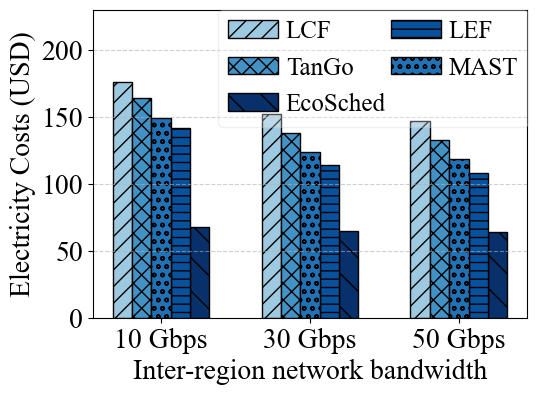

In [12]:
task_nums = [f'{bandwidth} Gbps' for bandwidth in TRANSFER_BANDWIDTH_LEVELS]
LCF = bandwidth_costs['LowestCostFirst']
LEF = bandwidth_costs['LowestEConFirst']
TanGO = bandwidth_costs['TanGo']
MAST = bandwidth_costs['MAST']
EcoSched = bandwidth_costs['CostPlanner']

bar_width = 0.13
x = np.arange(len(task_nums))
plt.figure(figsize=(5.6, 4))
plt.bar(x - 2 * bar_width, LCF, width=bar_width, color='#9ECAE1', label='LCF', edgecolor='black', hatch='//')
plt.bar(x - bar_width, TanGO, width=bar_width, color='#4292C6', label='TanGo', edgecolor='black', hatch='xx')
plt.bar(x + 2 * bar_width, EcoSched, width=bar_width, color='#08306B', label='EcoSched', edgecolor='black', hatch='\\')
plt.bar(x + bar_width, LEF, width=bar_width, color='#08519C', label='LEF', edgecolor='black', hatch='--')
plt.bar(x, MAST, width=bar_width, color='#2171B5', label='MAST', edgecolor='black', hatch='oo')

color_MCMF_list = ['#9ECAE1', '#4292C6', '#2171B5', '#08519C', '#08306B']

plt.xticks(x, task_nums)
plt.xlabel('Inter-region network bandwidth')
plt.ylabel('Electricity Costs (USD)')
plt.ylim(0, 230)
plt.yticks([0, 50, 100, 150, 200])
plt.legend(ncol=2, loc='upper left', bbox_to_anchor=(0.26, 1.04), framealpha=0.3, columnspacing=0.2, handletextpad=0.3, fontsize=18)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.savefig(OUTPUT_DIR / 'Electrity_Costs_Bandwidth_6000.pdf', format='pdf', bbox_inches='tight')
plt.show()
